#### Installatie van de open-source solver MIP en pakketten:

Deze notebook gebruikt de Mixed Integer Programming solver **MIP** en pakketten pandas en matplotlib.

Met onderstaande code worden deze geïnstalleerd (als dat nog niet het geval zou zijn).

In [1]:
for pkg in ["mip", "pandas", "matplotlib"]:
    try:
        __import__(pkg)
    except ImportError:
        get_ipython().run_line_magic("pip", f"install {pkg}")

from mip import *

In [2]:
from mip import * #Model, xsum, BINARY, INTEGER, CONTINUOUS, MINIMIZE
import pandas as pd
import math
import matplotlib.pyplot as plt; plt.rcdefaults()
import time

pd.set_option('display.max_rows',200) #number of rows to be displayed when a df is printedb

#### Probleemformulering

##### Verzamelingen

$L = \{1, \dots, n\}$ → Ladingen  
$K = \{50;\ 50.5;\ \dots;\ 80\}$ → Mogelijke waarden voor de temperatuur na het smelten

##### Variabelen

$ss_l$ → Starttijdstip smelten van lading l  
$ds_l$ → Duur smelten van lading l  
$dv_l$ → Duur vermogen van lading l  
$sg_l$ → Starttijdstip gieten van lading l  
$dg_l$ → Duur gieten van lading l  
$ll_l$ → Loopduur van lading l (tijd tussen einde smelten en start gieten)  
$Tns_l$ → Temperatuur na het smelten van lading l  
$Tgi_l$ → Giettemperatuur van lading l  
$x_{lk}$ → 1 als lading l na het smelten temperatuur $k$ heeft, zoniet 0  
$w_{lk}$ → Hulpvariabele, gelijk aan $ll_l \cdot x_{lk}$

##### Parameters

$n$ → Aantal ladingen  
$T_{ong}$ → Omgevingstemperatuur  
$\theta_k$ → Helling van de afkoelcurve bij temperatuur na het smelten $k$ (rechte tussen $ll = 0$ en $ll = 240$)

$$
\begin{aligned}
\min \quad sg_n & + dg_n \quad && (1) \\
\min \quad dv_l & \quad && (2) \\
Tns_l &= 30 + 0.4\, dv_l && \forall l \in L \quad &(3) \\
ds_l &\ge dv_l && \forall l \in L \quad &(4) \\
ds_l &\ge 465 - 1.6\, dv_l && \forall l \in L \quad &(5) \\
Tns_l &= \sum_{k \in K} k\, x_{lk} && \forall l \in L \quad &(6) \\
ll_l &= \sum_{k \in K} w_{lk} && \forall l \in L \quad &(7) \\
w_{lk} &\le 240\, x_{lk} && \forall l \in L,\ k \in K \quad &(8) \\
Tgi_l &= Tns_l + \sum_{k \in K} \theta_k\, w_{lk} && \forall l \in L \quad &(9) \\
dg_l &= -284 + 10\, Tgi_l && \forall l \in L \quad &(10) \\
sg_{l-1} + dg_{l-1} &= sg_l && \forall l \in \{2, \dots, n\} \quad &(11) \\
ss_{l-1} + ds_{l-1} &\le ss_l && \forall l \in \{2, \dots, n\} \quad &(12) \\
ss_l + ds_l &\le sg_l && \forall l \in L \quad &(13) \\
sg_l - ss_l - ds_l &= ll_l && \forall l \in L \quad &(14) \\
ss_l, sg_l, ds_l, dg_l, dv_l &\in \mathbb{R}_+; \quad w_{lk} \in \mathbb{R}_+; \quad x_{lk} \in \{0, 1\} \\
0 \le ll_l &\le 240 \\
50 \le Tns_l &\le 80; \quad 50 \le Tgi_l \le 80 \\
\theta_k &= \frac{T_{ong} + (k - T_{ong})\, e^{-240/1750} - k}{240} \\
T_{ong} &= 20; \quad n = 5
\end{aligned}
$$

(1) → Minimaliseren van de makespan, dus het einde van het gieten van de laatste lading.  
(2) → Minimaliseren van de vermogen tijd, dus van energiegebruik.  
(3) → De temperatuur na het smelten hangt lineair af van de duur van het vermogen.  
(4), (5) → De duur van het smelten is het maximum van de duur van het vermogen en $465 - 1.6\, dv_l$.  
(6) → De temperatuur na het smelten neemt één van de waarden uit $K$ aan.  
(7), (8) → De loopduur wordt toegekend aan de gekozen temperatuur; voor alle andere waarden is $w_{lk} = 0$.  
(9) → Afkoeling tijdens de loopduur, per temperatuur na het smelten benaderd door een rechte.  
(10) → De duur van het gieten hangt af van de giettemperatuur.  
(11) → Het gieten van de volgende lading start meteen eens het gieten van de vorige lading gedaan is.  
(12) → Het smelten van de volgende lading mag pas starten eens het smelten van de vorige lading afgelopen is.  
(13) → Een lading mag pas gegoten worden eens het smelten van die lading afgelopen is.  
(14) → De loopduur is de tijd tussen het einde van het smelten en de start van het gieten.

#### Modelimplementatie

In [3]:
# Newtons afkoelingswet
def newton(Tong, Tns, ll, tau=1750):
    """Exacte afkoeling volgens Newton."""
    return Tong + (Tns - Tong) * math.exp(-ll / tau)

In [4]:
def bouw_model(n_ladingen=5, Tong=20, stap=0.5, Tgi_min=50, verbose=False):
    """Bouwt het MILP en geeft het model en een dict met variabelen/expressies terug."""
    L = range(1, n_ladingen + 1)
    K = np.arange(50, 80 + stap / 2, stap).tolist()
    theta = {k: (newton(Tong, k, 240) - k) / 240 for k in K}

    model = Model("Schedule melting-casting", sense=MINIMIZE, solver_name="CBC")
    model.verbose = 1 if verbose else 0

    def vars_l(name, lb=0, ub=None):
        # {l: Var}, vergelijkbaar met model.addVars(L, ...)
        kw = dict(lb=lb, var_type=CONTINUOUS)
        if ub is not None:
            kw["ub"] = ub
        return {l: model.add_var(name=f"{name}[{l}]", **kw) for l in L}

    sg  = vars_l("start_gieten")
    ss  = vars_l("start_smelten")
    dg  = vars_l("duur_gieten")
    ds  = vars_l("duur_smelten")
    dv  = vars_l("duur_vermogen")
    ll  = vars_l("loopduur_lading", ub=240)
    Tns = vars_l("temperatuur_na_smelten", lb=50, ub=80)
    Tgi = vars_l("temperatuur_gieten", lb=Tgi_min, ub=80)
    x = {(l, k): model.add_var(name=f"x[{l},{k}]", var_type=BINARY) for l in L for k in K}
    w = {(l, k): model.add_var(name=f"w[{l},{k}]", lb=0, var_type=CONTINUOUS) for l in L for k in K}

    for l in L:
        model += 30 + 0.4 * dv[l] == Tns[l]
        model += dv[l] <= ds[l]
        model += 465 - 1.6 * dv[l] <= ds[l]
        model += Tns[l] == xsum(k * x[l, k] for k in K)
        model += ll[l] == xsum(w[l, k] for k in K)
        for k in K:
            model += w[l, k] <= 240 * x[l, k]
        model += Tgi[l] == Tns[l] + xsum(theta[k] * w[l, k] for k in K)
        model += -284 + 10 * Tgi[l] == dg[l]
        model += ss[l] + ds[l] <= sg[l]
        model += sg[l] - ss[l] - ds[l] == ll[l]

    for l in range(2, n_ladingen + 1):
        model += sg[l - 1] + dg[l - 1] == sg[l]
        model += ss[l - 1] + ds[l - 1] <= ss[l]

    makespan = sg[n_ladingen] + dg[n_ladingen] - ss[1]
    vermogen = xsum(dv[l] for l in L)

    # epsilon-constraint op het totale vermogen (eerst niet actief)
    # Aanpassen via: v["eps"].rhs = waarde
    eps = model.add_constr(vermogen <= 1e9, name="eps_vermogen")

    v = dict(L=L, Tong=Tong, sg=sg, ss=ss, dg=dg, ds=ds, dv=dv, ll=ll,
             Tns=Tns, Tgi=Tgi, makespan=makespan, vermogen=vermogen, eps=eps)
    return model, v

In [5]:
def los_op(model, v, eerst="makespan", tol=1e-6):
    """Lexicografisch oplossen: eerst de ene doelstelling, dan de andere als tiebreaker.

    MIP heeft geen setObjectiveN, dus in twee stappen:
    1) minimaliseer de eerste doelstelling,
    2) fixeer die op zijn optimale waarde (+ tol) en minimaliseer de tweede.
    """
    tweede = "vermogen" if eerst == "makespan" else "makespan"

    model.sense = MINIMIZE
    model.objective = v[eerst]
    if model.optimize() != OptimizationStatus.OPTIMAL:
        return None
    opt_eerste = v[eerst].x

    vast = model.add_constr(v[eerst] <= opt_eerste + tol, name="lex_vast")
    try:
        model.objective = v[tweede]
        if model.optimize() != OptimizationStatus.OPTIMAL:
            return None
        return v["makespan"].x, v["vermogen"].x
    finally:
        model.remove(vast)          # zodat herhaalde oproepen niet ophopen
        model.objective = v[eerst]  # objective terugzetten

In [6]:
def resultaten(v):
    """Zet de oplossing om in een DataFrame per lading."""
    rijen = []
    for l in v["L"]:
        rijen.append({
            "Lading": l,
            "Start Smelten": v["ss"][l].x,
            "Einde Smelten": v["ss"][l].x + v["ds"][l].x,
            "Duur Smelten": v["ds"][l].x,
            "Duur Vermogen": v["dv"][l].x,
            "Temp na Smelten": v["Tns"][l].x,
            "Loopduur": v["ll"][l].x,
            "Start Gieten": v["sg"][l].x,
            "Einde Gieten": v["sg"][l].x + v["dg"][l].x,
            "Duur Gieten": v["dg"][l].x,
            "Temp Gieten": v["Tgi"][l].x,
            "Temp Gieten (exact)": newton(v["Tong"], v["Tns"][l].x, v["ll"][l].x),
        })
    return pd.DataFrame(rijen).round(2)

In [7]:
def pareto_front(delta=1.0, max_iter=200, tol=1e-6, **kwargs):
    """
    Pareto-front makespan vs. vermogentijd:
    0. bepaal de ondergrens van het vermogen (minimaliseer vermogen),
    1. minimaliseer makespan met vermogen vrij (bovengrens),
    2. eis vermogen <= vorige vermogen - delta (maar nooit onder de ondergrens),
    3. stop zodra de ondergrens bereikt is.
    """
    model, v = bouw_model(**kwargs)
    v["eps"].rhs = 1e9

    # Rand 2: minimaal vermogen (met kleinste makespan daarbij)
    rand = los_op(model, v, eerst="vermogen")
    if rand is None:
        raise RuntimeError("Model onhaalbaar")
    p_min = rand[1]

    punten, schemas = [], []
    for it in range(max_iter):
        sol = los_op(model, v, eerst="makespan")
        if sol is None:
            break
        m, en = sol
        punten.append({"Stap": it, "Makespan": m, "Vermogen": en, "Grens vermogen": v["eps"].rhs})
        schemas.append(resultaten(v))
        if en <= p_min + tol:                        # ondergrens bereikt: klaar
            break
        v["eps"].rhs = max(en - delta, p_min)        # niet onder de rand zakken

    front = pd.DataFrame(punten).round(2)
    front.loc[0, "Grens vermogen"] = np.inf
    return front, schemas

In [8]:
def plot_pareto(front, extra=None):
    """Plot de Pareto-front; extra = lijst van (makespan, vermogen, label) om te vergelijken."""
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(front["Vermogen"], front["Makespan"], "-", label="Pareto-front")
    for m, e, lab in (extra or []):
        ax.plot(e, m, "s", label=lab)
    ax.set_xlabel("Totale vermogentijd (s)")
    ax.set_ylabel("Makespan (s)")
    ax.set_title("Pareto-front: makespan vs. vermogentijd")
    ax.grid(linestyle="--", alpha=0.7)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [9]:
def plot_gantt(result, makespan):
    """Gantt-chart van één schema."""
    fig, ax = plt.subplots(figsize=(12, 5))
    for _, row in result.iterrows():
        l = int(row["Lading"])
        w = row["Duur Vermogen"]
        ax.barh(y=3, width=w, left=row["Start Smelten"], color="orange", edgecolor="black", label="Vermogen")
        ax.text(row["Start Smelten"] + w/2, 3, f"L{l}\npv={w:.0f}", va="center", ha="center", fontsize=8)

        w = row["Duur Smelten"]
        ax.barh(y=2, width=w, left=row["Start Smelten"], color="skyblue", edgecolor="black", label="Smelten")
        ax.text(row["Start Smelten"] + w/2, 2, f"L{l}\nps={w:.0f}", va="center", ha="center", fontsize=8)

        if row["Loopduur"] > 0.5:
            w = row["Loopduur"]
            ax.barh(y=1, width=w, left=row["Einde Smelten"], color="none", edgecolor="grey", hatch="//", label="Loopduur")
            ax.text(row["Einde Smelten"] + w/2, 1, f"L{l}\nll={w:.0f}", va="center", ha="center", fontsize=8)

        w = row["Duur Gieten"]
        ax.barh(y=0, width=w, left=row["Start Gieten"], color="lightgreen", edgecolor="black", label="Gieten")
        ax.text(row["Start Gieten"] + w/2, 0, f"L{l}\npg={w:.0f}", va="center", ha="center", fontsize=8)

    ax.set_yticks([0, 1, 2, 3])
    ax.set_yticklabels(["Gieten", "Loopduur", "Smelten", "Vermogen"])
    ax.set_xlabel("Tijd (s)")
    ax.set_title(f"Productieschema (makespan = {makespan:.0f} s)")
    ax.grid(axis="x", linestyle="--", alpha=0.7)
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(), title="Processen", loc="upper right")
    plt.tight_layout()
    plt.show()

#### Resultaten en visualisatie

In [10]:
front, schemas = pareto_front(delta=5, Tgi_min=50.13)

##### Minimum makespan

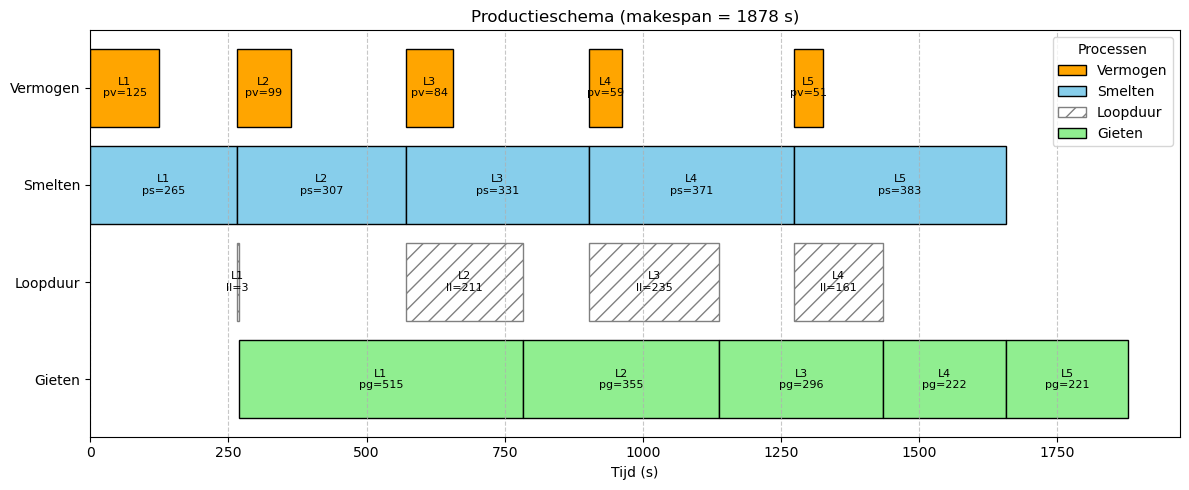

In [11]:
plot_gantt(schemas[0],  front.loc[0, "Makespan"])

##### Minimum energiegebruik/vermogingtijd

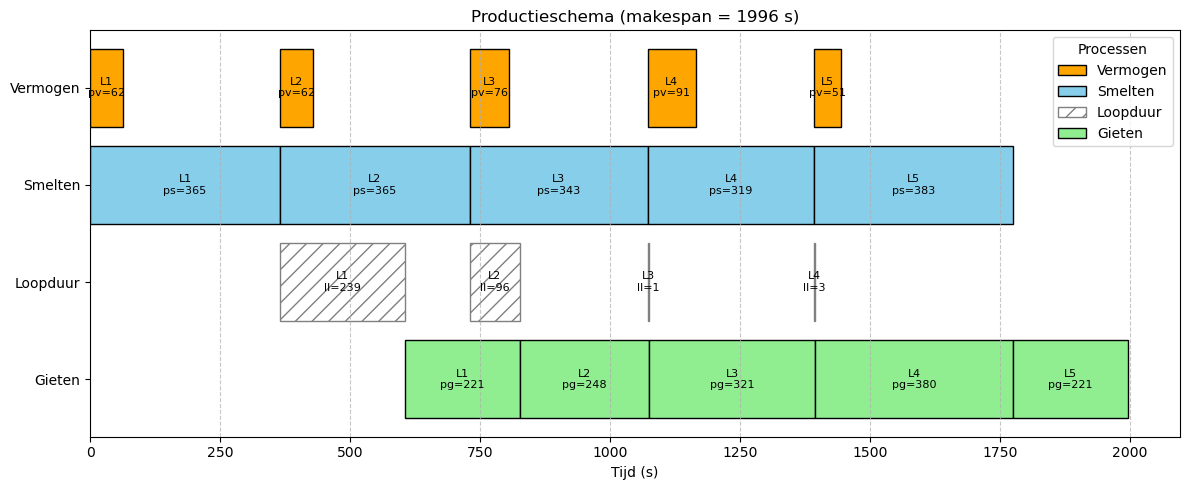

In [12]:
plot_gantt(schemas[-1], front.loc[len(front) - 1, "Makespan"])

##### Pareto grens

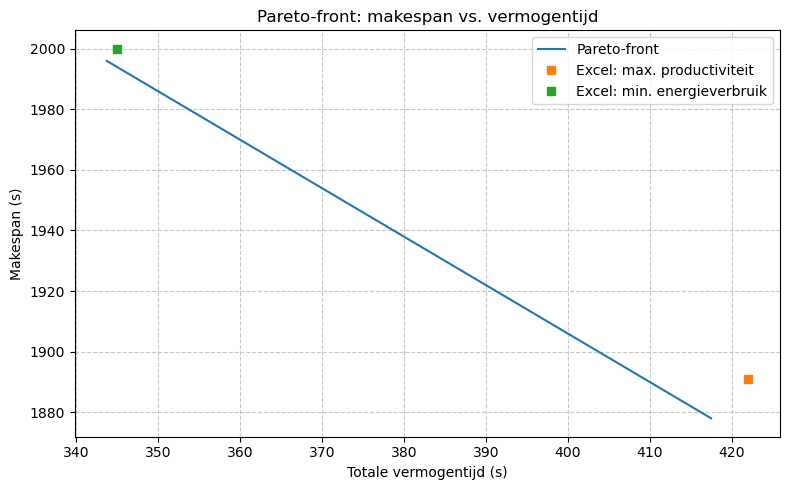

In [13]:
plot_pareto(front, extra=[(1891, 422, "Excel: max. productiviteit"),
                          (2000, 345, "Excel: min. energieverbruik")])

In [14]:
display(front)


,Stap,Makespan,Vermogen,Grens vermogen
0,0,1878.0,417.50,inf
1,1,1886.0,412.50,412.50
2,2,1894.0,407.50,407.50
3,3,1902.0,402.50,402.50
4,4,1910.0,397.50,397.50
5,5,1918.0,392.50,392.50
6,6,1926.0,387.50,387.50
7,7,1934.0,382.50,382.50
8,8,1942.0,377.50,377.50
9,9,1950.0,372.50,372.50
